# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

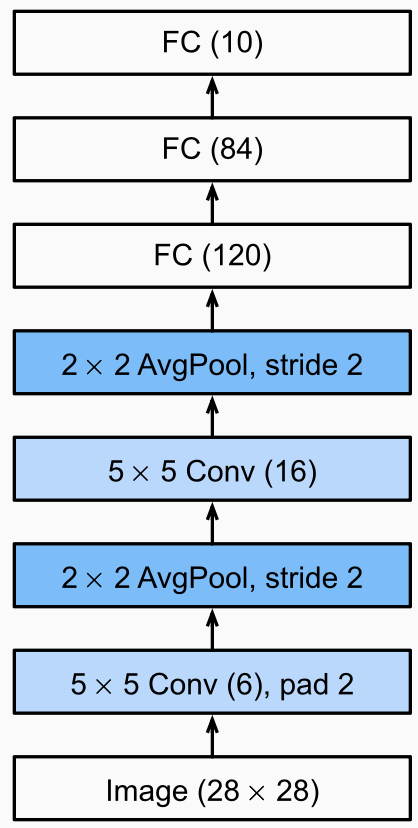

In [10]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    DataLoader,
    Subset
)

from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [11]:
# Cấu hình
IMG_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-3
NUM_WORKERS = 0
SEED = 42
NUM_CLASSES = 21

# Thiết lập device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Thiết lập seed để tái lập kết quả
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Device: cpu
Image size: 64
Batch size: 32
Epochs: 20
Learning rate: 0.001


In [12]:
# Đường dẫn dataset
train_dir = "VinaFood21/train"
test_dir = "VinaFood21/test"

# Kiểm tra đường dẫn
assert os.path.exists(train_dir), "Không tìm thấy thư mục train!"
assert os.path.exists(test_dir), "Không tìm thấy thư mục test!"

# Transform cho tập train: có augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transform cho validation và test: không augmentation
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load dataset train với hai transform
full_train_aug = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)

full_train_eval = datasets.ImageFolder(
    root=train_dir,
    transform=eval_transform
)

# Load dataset test
test_ds = datasets.ImageFolder(
    root=test_dir,
    transform=eval_transform
)

# Danh sách lớp
CLASSES = full_train_aug.classes

print("Số lớp:", len(CLASSES))
print("Danh sách lớp:", CLASSES)

assert len(CLASSES) == NUM_CLASSES
assert full_train_aug.classes == test_ds.classes

Số lớp: 21
Danh sách lớp: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']


In [15]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Đường dẫn dữ liệu
root = "VinaFood21"

train_dir = f"{root}/train"
val_dir = f"{root}/val"
test_dir = f"{root}/test"

# Transform cho tập train
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transform cho validation và test
eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load dataset
train_ds = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

# Danh sách 21 lớp
CLASSES = train_ds.classes

# Kiểm tra thứ tự lớp giữa các tập
assert train_ds.classes == val_ds.classes
assert train_ds.classes == test_ds.classes
assert len(CLASSES) == 21

# Tạo DataLoader
train_dl = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_dl = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

test_dl = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# Thống kê dữ liệu
print("Số lớp:", len(CLASSES))
print("Danh sách lớp:", CLASSES)

print("\nTrain samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))

print("\nTrain batches:", len(train_dl))
print("Validation batches:", len(val_dl))
print("Test batches:", len(test_dl))

Số lớp: 21
Danh sách lớp: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']

Train samples: 8035
Validation samples: 2009
Test samples: 6682

Train batches: 252
Validation batches: 63
Test batches: 209


In [38]:
xb, yb = next(iter(train_dl))

print("Image shape:", xb.shape)
print("Label shape:", yb.shape)

print("Min pixel:", xb.min().item())
print("Max pixel:", xb.max().item())

assert xb.shape[1:] == (3, 64, 64)
assert len(CLASSES) == 21

Image shape: torch.Size([16, 3, 64, 64])
Label shape: torch.Size([16])
Min pixel: -2.1007792949676514
Max pixel: 2.640000104904175


In [39]:
class LeNet5(nn.Module):

    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):

        super().__init__()

        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d

        # Convolution layers
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)

        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)

        # Tính số chiều sau Flatten
        n_flat = self._flat_dim(in_ch, img)

        # Fully connected layers
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):

        with torch.no_grad():

            z = torch.zeros(1, in_ch, img, img)

            z = self.s4(
                self.c3(
                    self.s2(
                        self.c1(z)
                    )
                )
            )

        return int(z.flatten(1).shape[1])

    def forward(self, x):

        x = self.s2(torch.relu(self.c1(x)))

        x = self.s4(torch.relu(self.c3(x)))

        x = x.flatten(1)

        x = torch.relu(self.f5(x))

        x = torch.relu(self.f6(x))

        return self.out(x)

In [40]:
# Hàm tính số tham số
def n_params(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


# Khởi tạo mô hình AvgPool
lenet = LeNet5(
    in_ch=3,
    img=64,
    num_classes=21,
    pool="avg"
).to(device)

print("Số chiều sau Flatten:", lenet.n_flat)

print("Tổng số tham số:", f"{n_params(lenet):,}")

assert lenet.n_flat == 2704
assert n_params(lenet) == 339421

Số chiều sau Flatten: 2704
Tổng số tham số: 339,421


In [41]:
def layer_table(model, img, in_ch=3):

    model_device = next(model.parameters()).device

    x = torch.zeros(
        1, in_ch, img, img,
        device=model_device
    )

    rows = []
    total = 0

    for name, layer in [
        ("C1", model.c1),
        ("S2", model.s2),
        ("C3", model.c3),
        ("S4", model.s4)
    ]:

        x = layer(x)

        p = n_params(layer)
        total += p

        shape = "x".join(
            map(str, tuple(x.shape)[1:])
        )

        rows.append((name, shape, p))

    x = x.flatten(1)

    rows.append(("Flatten", str(x.shape[1]), 0))

    for name, layer in [
        ("F5", model.f5),
        ("F6", model.f6),
        ("OUT", model.out)
    ]:

        x = layer(x)

        p = n_params(layer)
        total += p

        rows.append((name, str(x.shape[1]), p))

    return rows, total


rows, total = layer_table(lenet, 64)

df_layers = pd.DataFrame(
    rows,
    columns=["Layer", "Output Shape", "Parameters"]
)

display(df_layers)

print("Tổng số tham số:", f"{total:,}")

assert total == 339421

,Layer,Output Shape,Parameters
0,C1,6x60x60,456
1,S2,6x30x30,0
2,C3,16x26x26,2416
3,S4,16x13x13,0
4,Flatten,2704,0
5,F5,120,324600
6,F6,84,10164
7,OUT,21,1785


Tổng số tham số: 339,421


In [42]:
# Lấy một batch từ tập train
xb, yb = next(iter(train_dl))

xb = xb.to(device)
yb = yb.to(device)

lenet.eval()

with torch.no_grad():
    logits = lenet(xb)

print("Input shape:", xb.shape)
print("Label shape:", yb.shape)
print("Logits shape:", logits.shape)

assert logits.shape == (xb.shape[0], 21)

Input shape: torch.Size([16, 3, 64, 64])
Label shape: torch.Size([16])
Logits shape: torch.Size([16, 21])


In [34]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total = 0
    correct = 0
    running_loss = 0.0

    for xb, yb in loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)

        loss = criterion(logits, yb)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * yb.size(0)

        pred = logits.argmax(1)

        correct += (pred == yb).sum().item()

        total += yb.size(0)

    return running_loss / total, correct / total

In [43]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):

    model.eval()

    total = 0
    correct = 0
    running_loss = 0.0

    y_true = []
    y_pred = []

    for xb, yb in loader:

        xb = xb.to(device)
        yb = yb.to(device)

        logits = model(xb)

        loss = criterion(logits, yb)

        running_loss += loss.item() * yb.size(0)

        pred = logits.argmax(1)

        correct += (pred == yb).sum().item()

        total += yb.size(0)

        y_true.extend(yb.cpu().tolist())
        y_pred.extend(pred.cpu().tolist())

    return (
        running_loss / total,
        correct / total,
        y_true,
        y_pred
    )

In [44]:
def run_experiment(
    pool_type,
    train_dl,
    val_dl,
    test_dl,
    epochs=20,
    lr=1e-3
):

    print("\n" + "=" * 50)
    print(f"LENET - {pool_type.upper()}POOL")
    print("=" * 50)

    set_seed(SEED)

    model = LeNet5(
        in_ch=3,
        img=64,
        num_classes=21,
        pool=pool_type
    ).to(device)

    print("Số tham số:", f"{n_params(model):,}")

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = []

    for ep in range(1, epochs + 1):

        tr_loss, tr_acc = train_one_epoch(
            model, train_dl, criterion, optimizer, device
        )

        va_loss, va_acc, _, _ = evaluate(
            model, val_dl, criterion, device
        )

        history.append({
            "epoch": ep,
            "train_loss": tr_loss,
            "train_acc": tr_acc,
            "val_loss": va_loss,
            "val_acc": va_acc
        })

        print(
            f"Epoch {ep:02d}/{epochs} | "
            f"Train Loss: {tr_loss:.4f} | "
            f"Train Acc: {tr_acc:.4f} | "
            f"Val Loss: {va_loss:.4f} | "
            f"Val Acc: {va_acc:.4f}"
        )

    # Đánh giá trên tập test
    test_loss, test_acc, y_true, y_pred = evaluate(
        model, test_dl, criterion, device
    )

    print("\nTest Loss:", round(test_loss, 4))
    print("Test Accuracy:", round(test_acc, 4))

    return model, history, y_true, y_pred

In [18]:
model_avg, hist_avg, y_true_avg, y_pred_avg = run_experiment(
    pool_type="avg",
    train_dl=train_dl,
    val_dl=val_dl,
    test_dl=test_dl,
    epochs=20,
    lr=1e-3
)


LENET - AVGPOOL
Số tham số: 339,421


c:\Users\phucp\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 01/20 | Train Loss: 2.7268 | Train Acc: 0.1628 | Val Loss: 2.6073 | Val Acc: 0.1976
Epoch 02/20 | Train Loss: 2.4786 | Train Acc: 0.2402 | Val Loss: 2.4842 | Val Acc: 0.2404
Epoch 03/20 | Train Loss: 2.3295 | Train Acc: 0.2850 | Val Loss: 2.4623 | Val Acc: 0.2593
Epoch 04/20 | Train Loss: 2.1728 | Train Acc: 0.3348 | Val Loss: 2.4425 | Val Acc: 0.2693
Epoch 05/20 | Train Loss: 2.0035 | Train Acc: 0.3839 | Val Loss: 2.4656 | Val Acc: 0.2683
Epoch 06/20 | Train Loss: 1.7983 | Train Acc: 0.4395 | Val Loss: 2.4957 | Val Acc: 0.2778
Epoch 07/20 | Train Loss: 1.5802 | Train Acc: 0.5012 | Val Loss: 2.5958 | Val Acc: 0.2887
Epoch 08/20 | Train Loss: 1.3737 | Train Acc: 0.5695 | Val Loss: 2.7953 | Val Acc: 0.2867
Epoch 09/20 | Train Loss: 1.1476 | Train Acc: 0.6292 | Val Loss: 3.0327 | Val Acc: 0.2802
Epoch 10/20 | Train Loss: 0.9409 | Train Acc: 0.6979 | Val Loss: 3.2407 | Val Acc: 0.2847
Epoch 11/20 | Train Loss: 0.7447 | Train Acc: 0.7588 | Val Loss: 3.6686 | Val Acc: 0.2927
Epoch 12/2

In [19]:
model_max, hist_max, y_true_max, y_pred_max = run_experiment(
    pool_type="max",
    train_dl=train_dl,
    val_dl=val_dl,
    test_dl=test_dl,
    epochs=20,
    lr=1e-3
)


LENET - MAXPOOL
Số tham số: 339,421
Epoch 01/20 | Train Loss: 2.7338 | Train Acc: 0.1618 | Val Loss: 2.5935 | Val Acc: 0.2091
Epoch 02/20 | Train Loss: 2.4648 | Train Acc: 0.2403 | Val Loss: 2.5005 | Val Acc: 0.2509
Epoch 03/20 | Train Loss: 2.3068 | Train Acc: 0.2902 | Val Loss: 2.4325 | Val Acc: 0.2698
Epoch 04/20 | Train Loss: 2.1291 | Train Acc: 0.3406 | Val Loss: 2.4324 | Val Acc: 0.2643
Epoch 05/20 | Train Loss: 1.9385 | Train Acc: 0.3984 | Val Loss: 2.4364 | Val Acc: 0.2867
Epoch 06/20 | Train Loss: 1.7298 | Train Acc: 0.4576 | Val Loss: 2.4344 | Val Acc: 0.2937
Epoch 07/20 | Train Loss: 1.5029 | Train Acc: 0.5263 | Val Loss: 2.5396 | Val Acc: 0.3091
Epoch 08/20 | Train Loss: 1.2751 | Train Acc: 0.5919 | Val Loss: 2.7482 | Val Acc: 0.3116
Epoch 09/20 | Train Loss: 1.0341 | Train Acc: 0.6727 | Val Loss: 3.0067 | Val Acc: 0.3106
Epoch 10/20 | Train Loss: 0.8205 | Train Acc: 0.7420 | Val Loss: 3.3991 | Val Acc: 0.2937
Epoch 11/20 | Train Loss: 0.6278 | Train Acc: 0.7971 | Val Loss

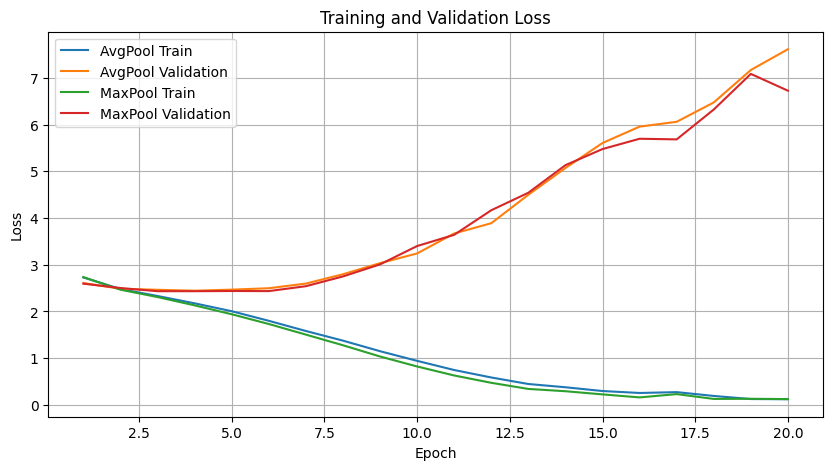

In [20]:
epochs = range(1, len(hist_avg) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    [h["train_loss"] for h in hist_avg],
    label="AvgPool Train"
)

plt.plot(
    epochs,
    [h["val_loss"] for h in hist_avg],
    label="AvgPool Validation"
)

plt.plot(
    epochs,
    [h["train_loss"] for h in hist_max],
    label="MaxPool Train"
)

plt.plot(
    epochs,
    [h["val_loss"] for h in hist_max],
    label="MaxPool Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [21]:
def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "F1-macro": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }


metrics_avg = calculate_metrics(
    y_true_avg, y_pred_avg
)

metrics_max = calculate_metrics(
    y_true_max, y_pred_max
)

results = pd.DataFrame(
    [metrics_avg, metrics_max],
    index=["LeNet-AvgPool", "LeNet-MaxPool"]
)

print("KẾT QUẢ TRÊN TẬP TEST")

display(results.round(4))

KẾT QUẢ TRÊN TẬP TEST


,Accuracy,Precision,Recall,F1-macro
LeNet-AvgPool,0.2357,0.2291,0.2335,0.2238
LeNet-MaxPool,0.2601,0.2540,0.2535,0.2488


In [22]:
report_avg = classification_report(
    y_true_avg,
    y_pred_avg,
    labels=list(range(21)),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

report_max = classification_report(
    y_true_max,
    y_pred_max,
    labels=list(range(21)),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

f1_table = pd.DataFrame({

    "Class": CLASSES,

    "F1-AvgPool": [
        report_avg[c]["f1-score"] for c in CLASSES
    ],

    "F1-MaxPool": [
        report_max[c]["f1-score"] for c in CLASSES
    ]

})

display(f1_table.round(4))

,Class,F1-AvgPool,F1-MaxPool
0,banh-can,0.1466,0.1485
1,banh-hoi,0.3221,0.3421
2,banh-mi-chao,0.1697,0.2446
3,banh-tet,0.1763,0.2340
4,banh-trang-tron,0.1193,0.0967
5,banh-u,0.1412,0.1446
6,banh-uot,0.2200,0.2388
7,bap-nuong,0.0819,0.0909
8,bo-kho,0.1837,0.2336
9,bo-la-lot,0.3739,0.3977


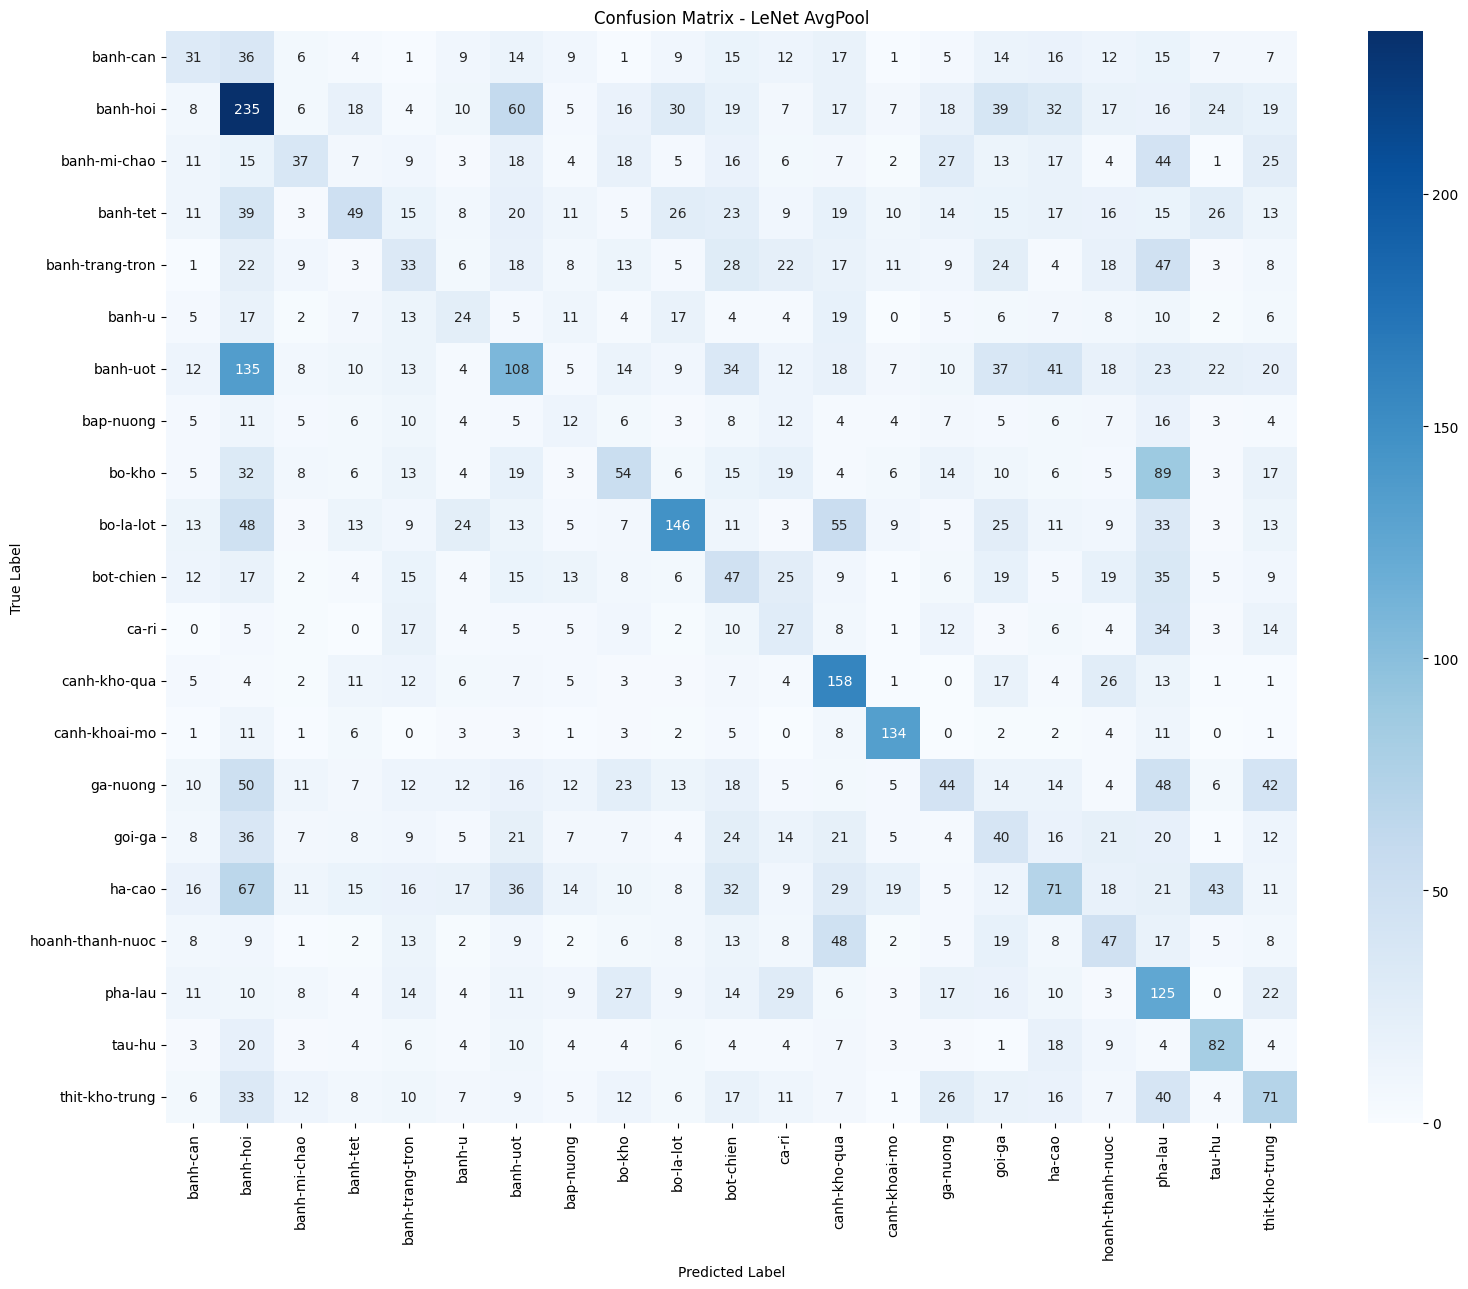

In [23]:
def plot_confusion_matrix(y_true, y_pred, title):

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(range(21))
    )

    plt.figure(figsize=(16, 13))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES
    )

    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    plt.xticks(rotation=90)
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    return cm


cm_avg = plot_confusion_matrix(
    y_true_avg,
    y_pred_avg,
    "Confusion Matrix - LeNet AvgPool"
)

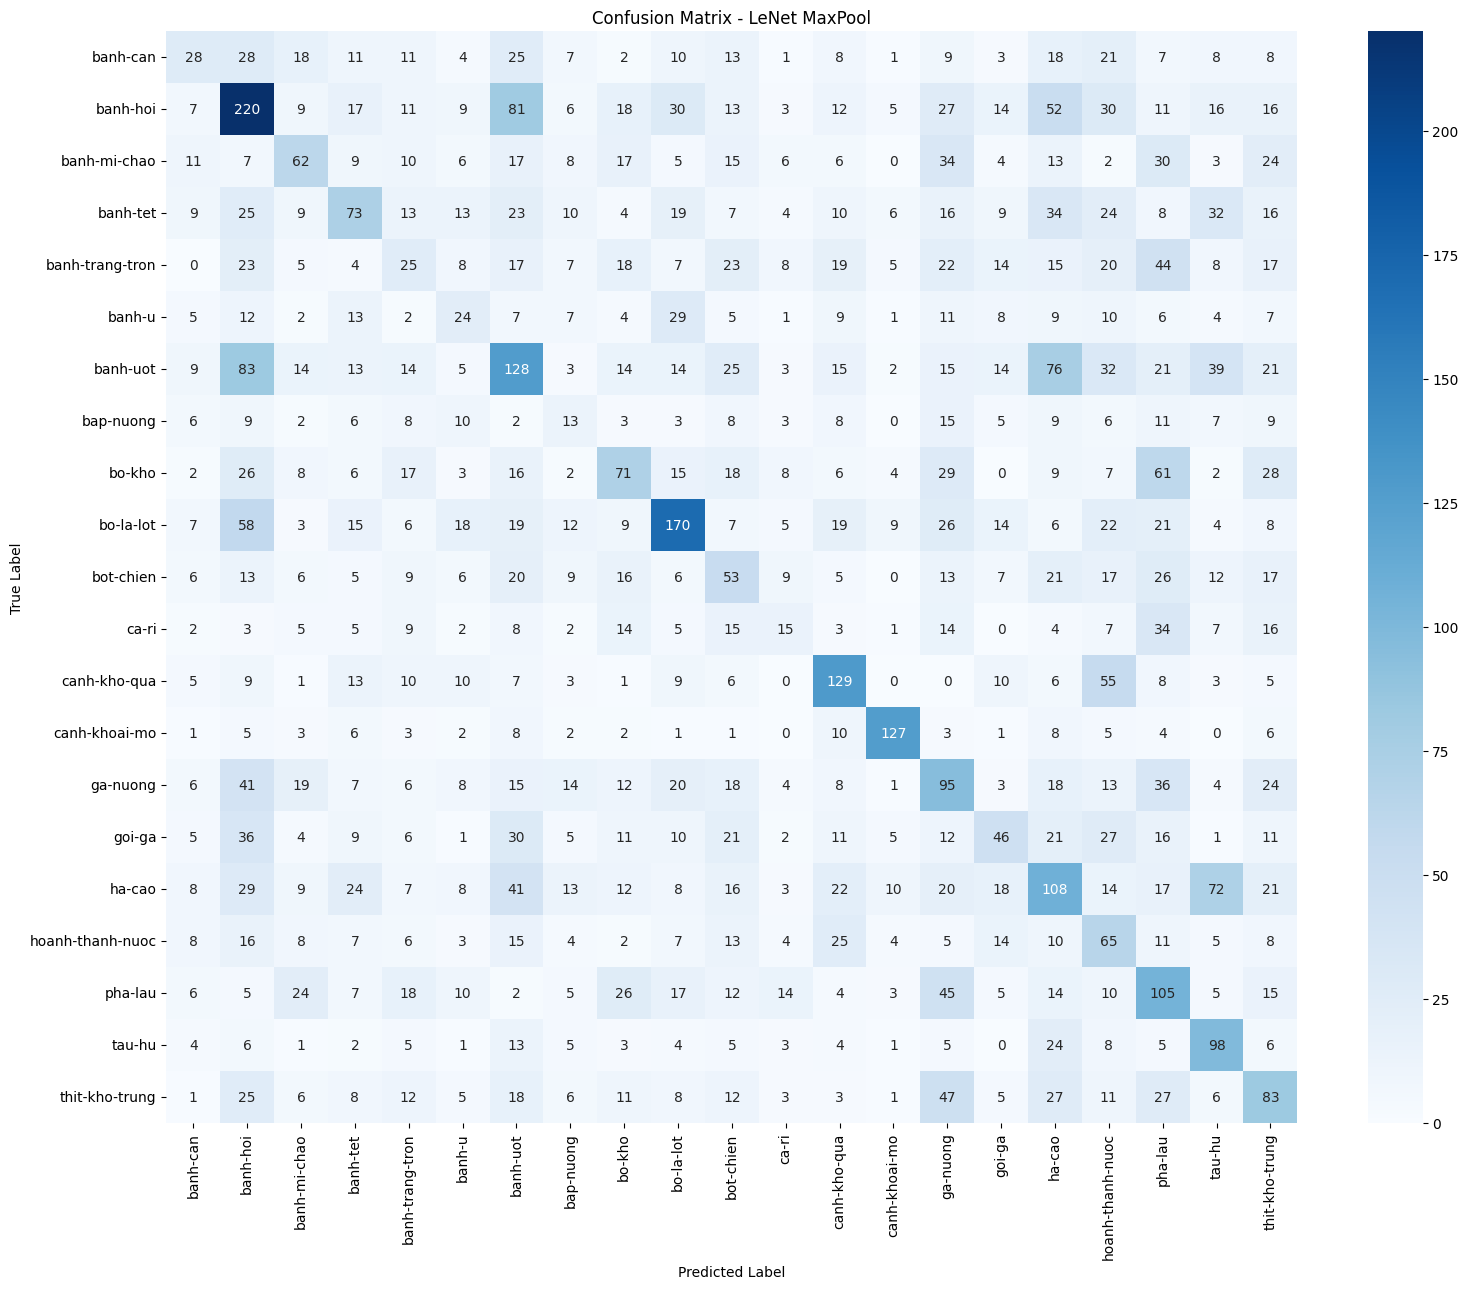

In [24]:
cm_max = plot_confusion_matrix(
    y_true_max,
    y_pred_max,
    "Confusion Matrix - LeNet MaxPool"
)

Macro-F1 AvgPool: 0.2238
Macro-F1 MaxPool: 0.2488


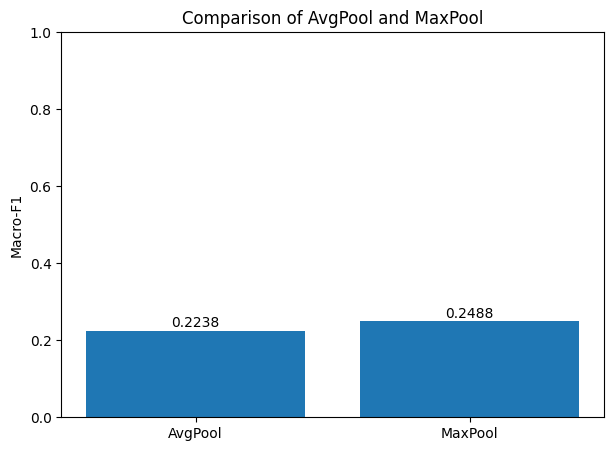

MaxPool có Macro-F1 cao hơn.


In [25]:
f1_avg = metrics_avg["F1-macro"]
f1_max = metrics_max["F1-macro"]

print(f"Macro-F1 AvgPool: {f1_avg:.4f}")
print(f"Macro-F1 MaxPool: {f1_max:.4f}")

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["AvgPool", "MaxPool"],
    [f1_avg, f1_max]
)

plt.ylabel("Macro-F1")
plt.title("Comparison of AvgPool and MaxPool")
plt.ylim(0, 1)

for bar, value in zip(bars, [f1_avg, f1_max]):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.show()

if f1_avg > f1_max:
    print("AvgPool có Macro-F1 cao hơn.")

elif f1_max > f1_avg:
    print("MaxPool có Macro-F1 cao hơn.")

else:
    print("Hai mô hình có Macro-F1 bằng nhau.")

In [26]:
final_results = pd.DataFrame({

    "Model": [
        "LeNet-AvgPool",
        "LeNet-MaxPool"
    ],

    "Parameters": [
        n_params(model_avg),
        n_params(model_max)
    ],

    "Accuracy": [
        metrics_avg["Accuracy"],
        metrics_max["Accuracy"]
    ],

    "Precision": [
        metrics_avg["Precision"],
        metrics_max["Precision"]
    ],

    "Recall": [
        metrics_avg["Recall"],
        metrics_max["Recall"]
    ],

    "F1-macro": [
        metrics_avg["F1-macro"],
        metrics_max["F1-macro"]
    ]

})

display(final_results.round(4))

,Model,Parameters,Accuracy,Precision,Recall,F1-macro
0,LeNet-AvgPool,339421,0.2357,0.2291,0.2335,0.2238
1,LeNet-MaxPool,339421,0.2601,0.2540,0.2535,0.2488


### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

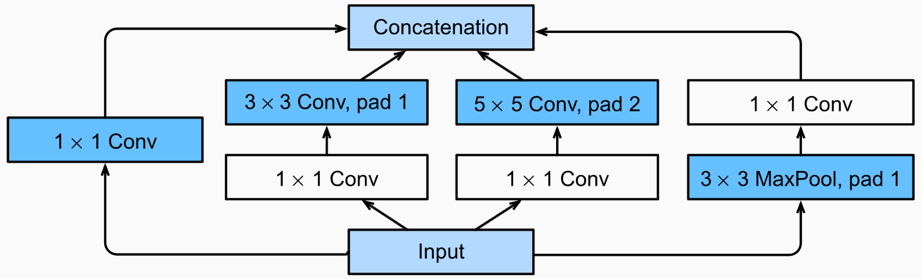

**GoogLeNet (Multi-branch Network)**

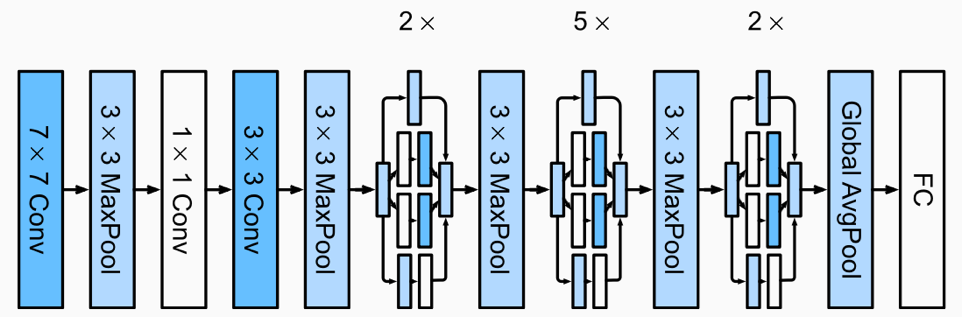

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()

        # Nhánh 1: convolution 1x1
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, kernel_size=1),
            nn.ReLU()
        )

        # Nhánh 2: 1x1 -> 3x3
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(f3r, f3, kernel_size=3, padding=1),
            nn.ReLU()
        )

        # Nhánh 3: 1x1 -> 5x5
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(f5r, f5, kernel_size=5, padding=2),
            nn.ReLU()
        )

        # Nhánh 4: MaxPool -> 1x1
        self.b4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, kernel_size=1),
            nn.ReLU()
        )

    def forward(self, x):
        return torch.cat([
            self.b1(x),
            self.b2(x),
            self.b3(x),
            self.b4(x)
        ], dim=1)

In [3]:
class GoogLeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()

        self.inception1 = InceptionBlock(
            3, 16, 16, 24, 4, 8, 8
        )
        self.pool1 = nn.MaxPool2d(2, 2)

        self.inception2 = InceptionBlock(
            56, 32, 32, 48, 8, 16, 16
        )
        self.pool2 = nn.MaxPool2d(2, 2)

        self.inception3 = InceptionBlock(
            112, 48, 48, 64, 8, 16, 16
        )
        self.pool3 = nn.MaxPool2d(2, 2)

        self.inception4 = InceptionBlock(
            144, 64, 64, 96, 16, 24, 24
        )

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(208, num_classes)

    def forward(self, x):
        x = self.inception1(x)
        x = self.pool1(x)

        x = self.inception2(x)
        x = self.pool2(x)

        x = self.inception3(x)
        x = self.pool3(x)

        x = self.inception4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        return self.fc(x)

In [16]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_dl = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_dl = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_dl = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train batches:", len(train_dl))
print("Validation batches:", len(val_dl))
print("Test batches:", len(test_dl))

Train batches: 503
Validation batches: 126
Test batches: 418


In [17]:
model = GoogLeNet(num_classes=21).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

start_time = time.time()

model.train()

for i, (images, labels) in enumerate(train_dl):
    if i == 5:
        break

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    print(f"Batch {i+1}/5 - Loss: {loss.item():.4f}")

print("Thời gian 5 batch:", round(time.time() - start_time, 2), "giây")

Batch 1/5 - Loss: 3.0355
Batch 2/5 - Loss: 3.0218
Batch 3/5 - Loss: 3.0335
Batch 4/5 - Loss: 3.0338
Batch 5/5 - Loss: 3.0585
Thời gian 5 batch: 5.45 giây


In [23]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = GoogLeNet(num_classes=21).to(device)

x = torch.rand(1, 3, 64, 64).to(device)

print("Input:", x.shape)

model.eval()

with torch.no_grad():

    x = model.inception1(x)
    print("Sau Inception 1:", x.shape)

    x = model.pool1(x)
    print("Sau Pool 1:", x.shape)

    x = model.inception2(x)
    print("Sau Inception 2:", x.shape)

    x = model.pool2(x)
    print("Sau Pool 2:", x.shape)

    x = model.inception3(x)
    print("Sau Inception 3:", x.shape)

    x = model.pool3(x)
    print("Sau Pool 3:", x.shape)

    x = model.inception4(x)
    print("Sau Inception 4:", x.shape)

    x = model.avgpool(x)
    print("Sau AdaptiveAvgPool2d:", x.shape)

    x = torch.flatten(x, 1)
    print("Sau Flatten:", x.shape)

    output = model.fc(x)
    print("Output:", output.shape)

print("\nTổng số tham số:",
      f"{n_params(model):,}")


Input: torch.Size([1, 3, 64, 64])
Sau Inception 1: torch.Size([1, 56, 64, 64])
Sau Pool 1: torch.Size([1, 56, 32, 32])
Sau Inception 2: torch.Size([1, 112, 32, 32])
Sau Pool 2: torch.Size([1, 112, 16, 16])
Sau Inception 3: torch.Size([1, 144, 16, 16])
Sau Pool 3: torch.Size([1, 144, 8, 8])
Sau Inception 4: torch.Size([1, 208, 8, 8])
Sau AdaptiveAvgPool2d: torch.Size([1, 208, 1, 1])
Sau Flatten: torch.Size([1, 208])
Output: torch.Size([1, 21])

Tổng số tham số: 164,821


In [24]:
blocks = [
    ("Inception 1", model.inception1),
    ("Inception 2", model.inception2),
    ("Inception 3", model.inception3),
    ("Inception 4", model.inception4)
]

for name, block in blocks:
    dummy = torch.rand(1, 3, 64, 64).to(device)

    # Đưa qua các block trước đó
    with torch.no_grad():
        for _, previous_block in blocks:
            if previous_block is block:
                break
            dummy = previous_block(dummy)

        output = block(dummy)

    print(
        f"{name}: "
        f"Output channels = {output.shape[1]}, "
        f"Parameters = {n_params(block):,}"
    )

print("\nTổng tham số toàn mô hình:", f"{n_params(model):,}")

Inception 1: Output channels = 56, Parameters = 4,464
Inception 2: Output channels = 112, Parameters = 22,104
Inception 3: Output channels = 144, Parameters = 44,488
Inception 4: Output channels = 208, Parameters = 89,376

Tổng tham số toàn mô hình: 164,821


In [25]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    start_time = time.time()

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_time = time.time() - start_time

    return total_loss / total, correct / total, epoch_time


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    y_true = []
    y_pred = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        total_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

    return (
        total_loss / total,
        correct / total,
        np.array(y_true),
        np.array(y_pred)
    )

In [26]:
EPOCHS = 20
LEARNING_RATE = 0.001

model = GoogLeNet(num_classes=21).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = []

for epoch in range(EPOCHS):
    train_loss, train_acc, epoch_time = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )

    val_loss, val_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "epoch_time": epoch_time
    })

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f} "
        f"Time: {epoch_time:.2f}s"
    )

c:\Users\phucp\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/20] Train Loss: 2.8802 Train Acc: 0.1205 Val Loss: 2.7616 Val Acc: 0.1712 Time: 304.31s
Epoch [2/20] Train Loss: 2.6291 Train Acc: 0.1741 Val Loss: 2.5213 Val Acc: 0.2125 Time: 278.22s
Epoch [3/20] Train Loss: 2.3917 Train Acc: 0.2489 Val Loss: 2.3933 Val Acc: 0.2568 Time: 282.75s
Epoch [4/20] Train Loss: 2.2373 Train Acc: 0.2910 Val Loss: 2.2618 Val Acc: 0.2947 Time: 294.44s
Epoch [5/20] Train Loss: 2.1174 Train Acc: 0.3352 Val Loss: 2.1552 Val Acc: 0.3206 Time: 280.24s
Epoch [6/20] Train Loss: 2.0118 Train Acc: 0.3612 Val Loss: 2.1181 Val Acc: 0.3370 Time: 284.67s
Epoch [7/20] Train Loss: 1.9217 Train Acc: 0.3961 Val Loss: 2.0313 Val Acc: 0.3649 Time: 293.78s
Epoch [8/20] Train Loss: 1.8355 Train Acc: 0.4195 Val Loss: 2.0680 Val Acc: 0.3718 Time: 293.14s
Epoch [9/20] Train Loss: 1.7667 Train Acc: 0.4398 Val Loss: 1.9852 Val Acc: 0.3768 Time: 281.45s
Epoch [10/20] Train Loss: 1.7058 Train Acc: 0.4553 Val Loss: 1.9004 Val Acc: 0.4042 Time: 282.99s
Epoch [11/20] Train Loss: 1.6

In [27]:
test_loss, test_acc, y_true, y_pred = evaluate(
    model, test_dl, criterion, device
)

precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

f1_macro = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("KẾT QUẢ ĐÁNH GIÁ GOOGLENET")
print("-" * 40)
print(f"Accuracy : {test_acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-macro : {f1_macro:.4f}")

KẾT QUẢ ĐÁNH GIÁ GOOGLENET
----------------------------------------
Accuracy : 0.4166
Precision: 0.4407
Recall   : 0.3922
F1-macro : 0.3933


In [28]:
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(21)),
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

per_class_f1 = pd.DataFrame({
    "Class": CLASSES,
    "F1-score": [
        report[name]["f1-score"] for name in CLASSES
    ]
})

display(per_class_f1)

,Class,F1-score
0,banh-can,0.268421
1,banh-hoi,0.512315
2,banh-mi-chao,0.448980
3,banh-tet,0.403883
4,banh-trang-tron,0.262042
5,banh-u,0.266667
6,banh-uot,0.411028
7,bap-nuong,0.205128
8,bo-kho,0.412121
9,bo-la-lot,0.569038


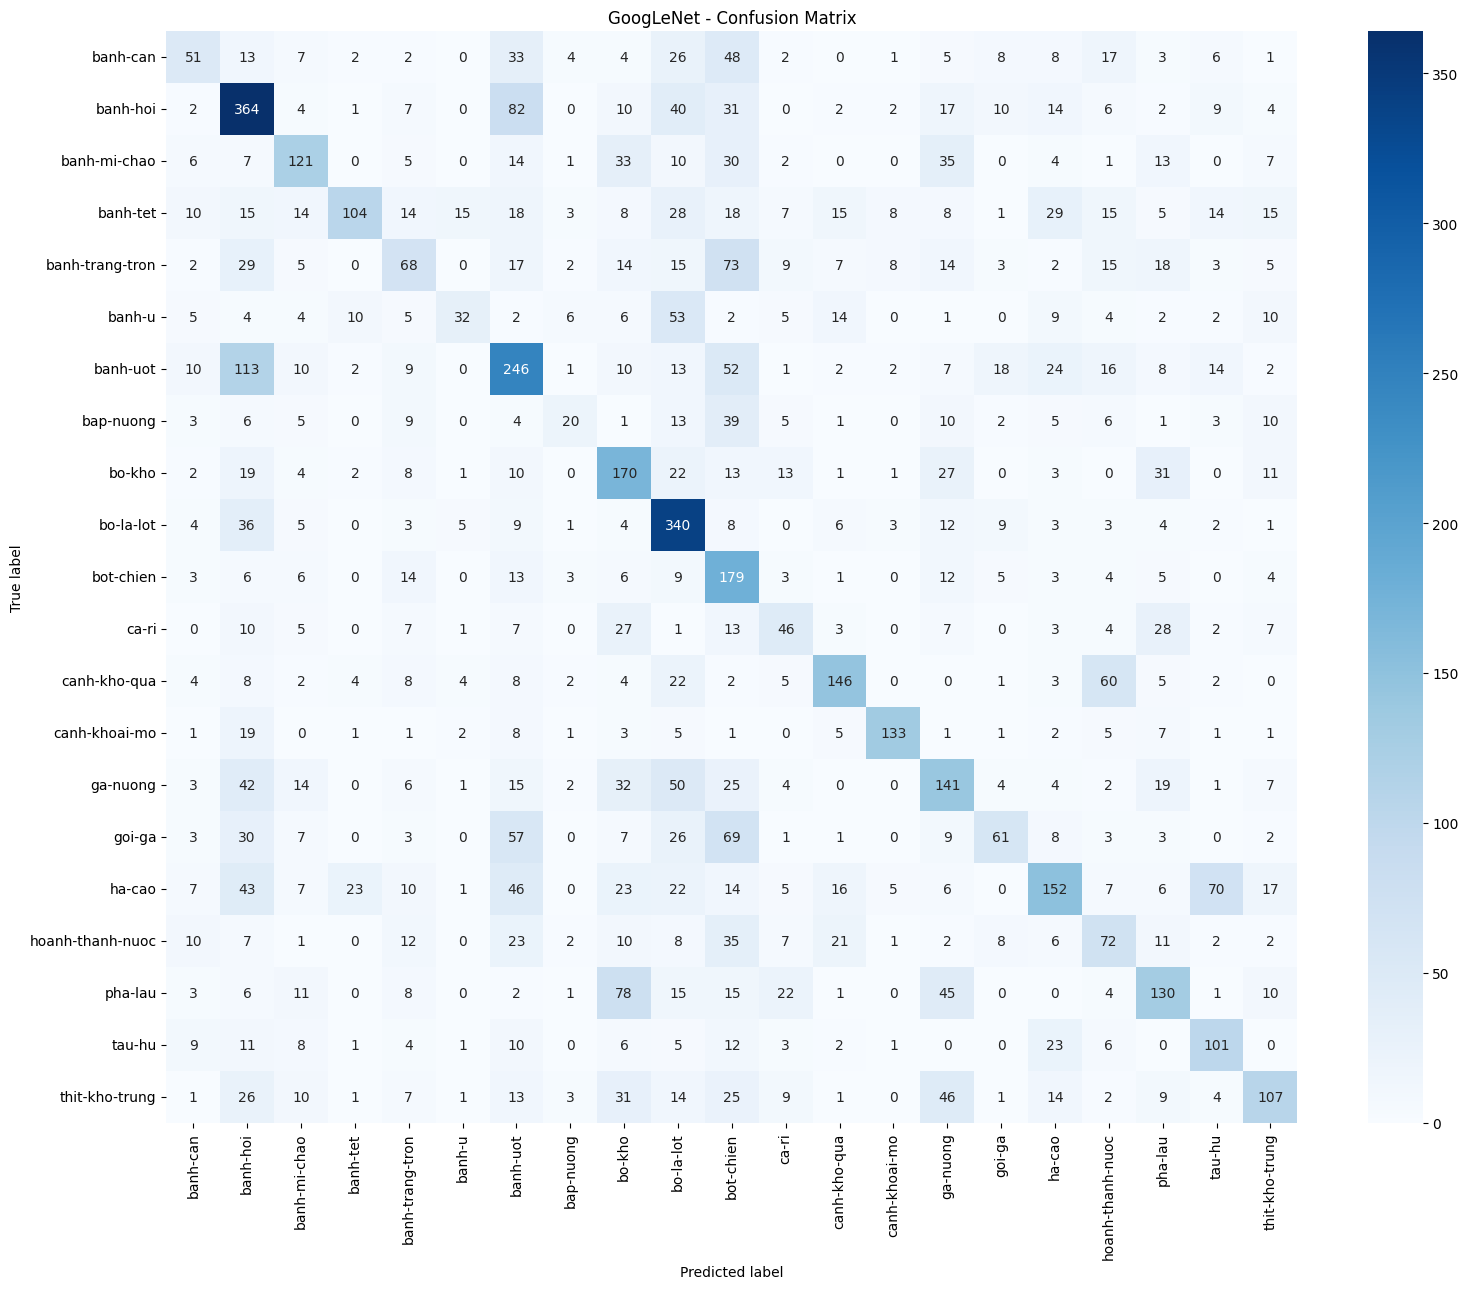

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(21))
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("GoogLeNet - Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [48]:
avg_epoch_time = np.mean([
    item["epoch_time"]
    for i, item in enumerate(history, start=1)
    if i != 11
])

googlenet_results = {
    "Model": "GoogLeNet",
    "Parameters": n_params(model),
    "Accuracy": test_acc,
    "Precision": precision,
    "Recall": recall,
    "F1-macro": f1_macro,
    "Avg epoch time (s)": avg_epoch_time
}

googlenet_df = pd.DataFrame([googlenet_results])
display(googlenet_df)

,Model,Parameters,Accuracy,Precision,Recall,F1-macro,Avg epoch time (s)
0,GoogLeNet,164821,0.416642,0.440696,0.392233,0.393264,297.738436


| Model         | Parameters | Accuracy | Precision | Recall | F1-macro | Epoch time (s) |
| ------------- | ---------- | -------- | --------- | ------ | -------- | -------------- |
| LeNet-AvgPool | 339,421    | 0.2357   | 0.2291    | 0.2335 | 0.2238   | -------------- |
| LeNet-MaxPool | 339,421    | 0.2601   | 0.2540    | 0.2535 | 0.2488   | -------------- |
| GoogLeNet     | 164,182    | 0.4166   | 0.4407    | 0.3922 | 0.3933   | 297.738436     |

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

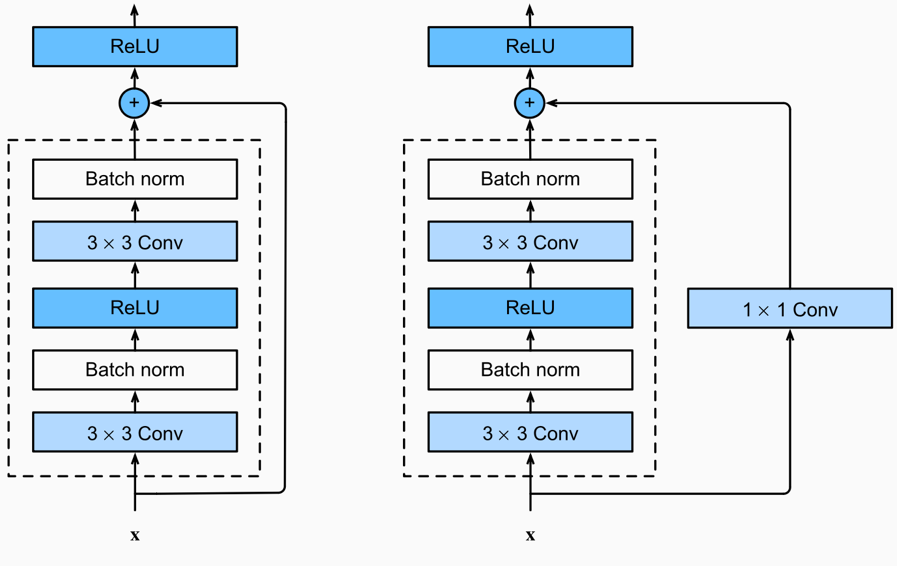

**ResNet**

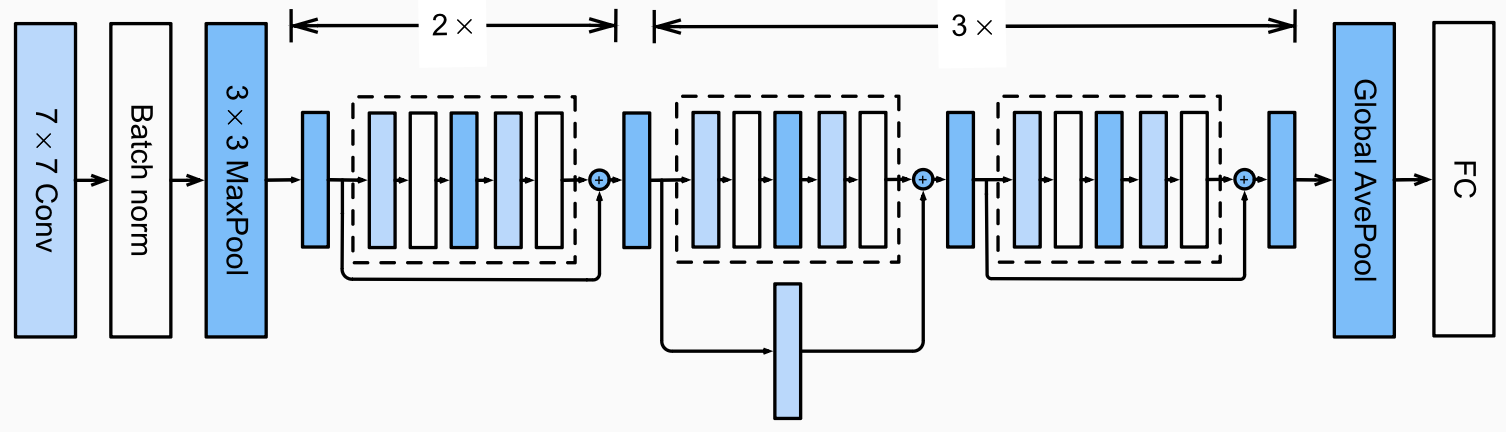

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.